<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Explorando_RF_DETR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install -U rfdetr supervision

In [ ]:
import os
import cv2
import time
import inspect
import requests
import numpy as np
import matplotlib.pyplot as plt
import supervision as sv
import rfdetr

from PIL import Image
from IPython.display import display, Video
from google.colab import files

print("RF-DETR:", getattr(rfdetr, "__version__", "versión no expuesta"))
print("OpenCV:", cv2.__version__)
print("Supervision:", sv.__version__)
print("GPU disponible:", __import__("torch").cuda.is_available())

RF-DETR: versión no expuesta
OpenCV: 4.14.0
Supervision: 0.31.4
GPU disponible: True


In [ ]:
print("Módulo instalado en:")
print(rfdetr.__file__)

print("\nClases de RF-DETR disponibles:\n")

for nombre in sorted(dir(rfdetr)):
    objeto = getattr(rfdetr, nombre)

    if (
        inspect.isclass(objeto)
        and ("RFDETR" in nombre or "RFDETR" in str(objeto))
    ):
        try:
            firma = inspect.signature(objeto)
        except (TypeError, ValueError):
            firma = "(firma no disponible)"

        print(f"{nombre}{firma}")

print("\nFunciones y clases públicas del módulo:")
print([n for n in dir(rfdetr) if not n.startswith("_")])

Módulo instalado en:
/usr/local/lib/python3.13/dist-packages/rfdetr/__init__.py

Clases de RF-DETR disponibles:

RFDETR(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRKeypointPreview(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRLarge(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRMedium(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRNano(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRSeg2XLarge(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRSegLarge(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRSegMedium(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRSegNano(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRSegSmall(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRSegXLarge(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'
RFDETRSmall(*, trust_chec

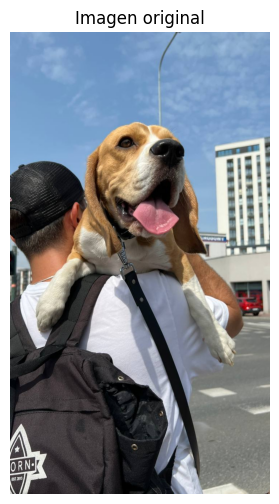

In [ ]:
url = "https://media.roboflow.com/dog.jpg"
ruta_imagen = "/content/imagen_prueba.jpg"

respuesta = requests.get(url, timeout=30)
respuesta.raise_for_status()

with open(ruta_imagen, "wb") as archivo:
    archivo.write(respuesta.content)

imagen = Image.open(ruta_imagen).convert("RGB")

plt.figure(figsize=(10, 6))
plt.imshow(imagen)
plt.title("Imagen original")
plt.axis("off")
plt.show()

In [ ]:
from rfdetr import RFDETRSmall

modelo = RFDETRSmall()

print("Modelo cargado:", type(modelo).__name__)

inicio = time.perf_counter()
detecciones = modelo.predict(imagen, threshold=0.5)
tiempo = time.perf_counter() - inicio

print("Tiempo de inferencia medido:", round(tiempo, 3), "s")
print("Número de detecciones:", len(detecciones))
print("Clases detectadas:", detecciones.class_id)
print("Confianzas:", detecciones.confidence)
print("Cajas [x1, y1, x2, y2]:")
print(detecciones.xyxy)

[2026-11-03 18:44:41] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-small.pth


/root/.roboflow/models/rf-detr-small.pth:   0%|          | 0.00/368M [00:00<?, ?iB/s]

[2026-11-03 18:45:00] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-small.pth


[2026-11-03 18:45:00] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-03 18:45:00] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-11-03 18:45:02] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.
Modelo cargado: RFDETRSmall


[2026-11-03 18:45:04] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Tiempo de inferencia medido: 3.62 s
Número de detecciones: 4
Clases detectadas: [18 27  1  3]
Confianzas: [0.9525871  0.65940475 0.58113164 0.53238475]
Cajas [x1, y1, x2, y2]:
[[6.8584793e+01 2.4794548e+02 6.2335492e+02 9.3097534e+02]
 [4.5453787e-01 6.5826599e+02 4.4207086e+02 1.2676451e+03]
 [0.0000000e+00 3.4972244e+02 6.4608435e+02 1.2638331e+03]
 [6.2278839e+02 7.1606763e+02 7.0154681e+02 7.8712292e+02]]


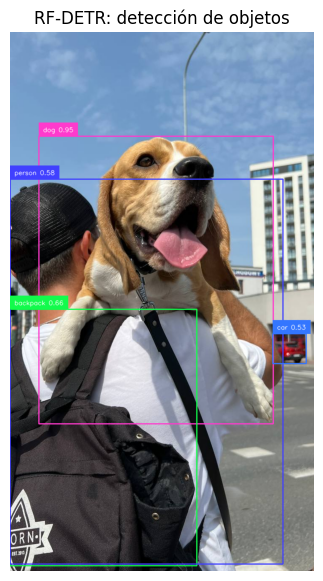

In [ ]:
# Convertir la imagen a un arreglo RGB
imagen_np = np.array(imagen)

# Recuperar nombres de clase del modelo o del conjunto COCO
try:
    nombres = detecciones.data.get("class_name", None)

    if nombres is None:
        from rfdetr.assets.coco_classes import COCO_CLASSES
        nombres = [
            COCO_CLASSES[int(i)]
            if 0 <= int(i) < len(COCO_CLASSES)
            else f"clase_{i}"
            for i in detecciones.class_id
        ]
    else:
        nombres = list(nombres)

except Exception:
    nombres = [f"clase_{i}" for i in detecciones.class_id]

etiquetas = [
    f"{nombre} {conf:.2f}"
    for nombre, conf in zip(nombres, detecciones.confidence)
]

anotador_cajas = sv.BoxAnnotator()
anotador_etiquetas = sv.LabelAnnotator()

resultado = anotador_cajas.annotate(
    scene=imagen_np.copy(),
    detections=detecciones
)

resultado = anotador_etiquetas.annotate(
    scene=resultado,
    detections=detecciones,
    labels=etiquetas
)

plt.figure(figsize=(12, 7))
plt.imshow(resultado)
plt.title("RF-DETR: detección de objetos")
plt.axis("off")
plt.show()

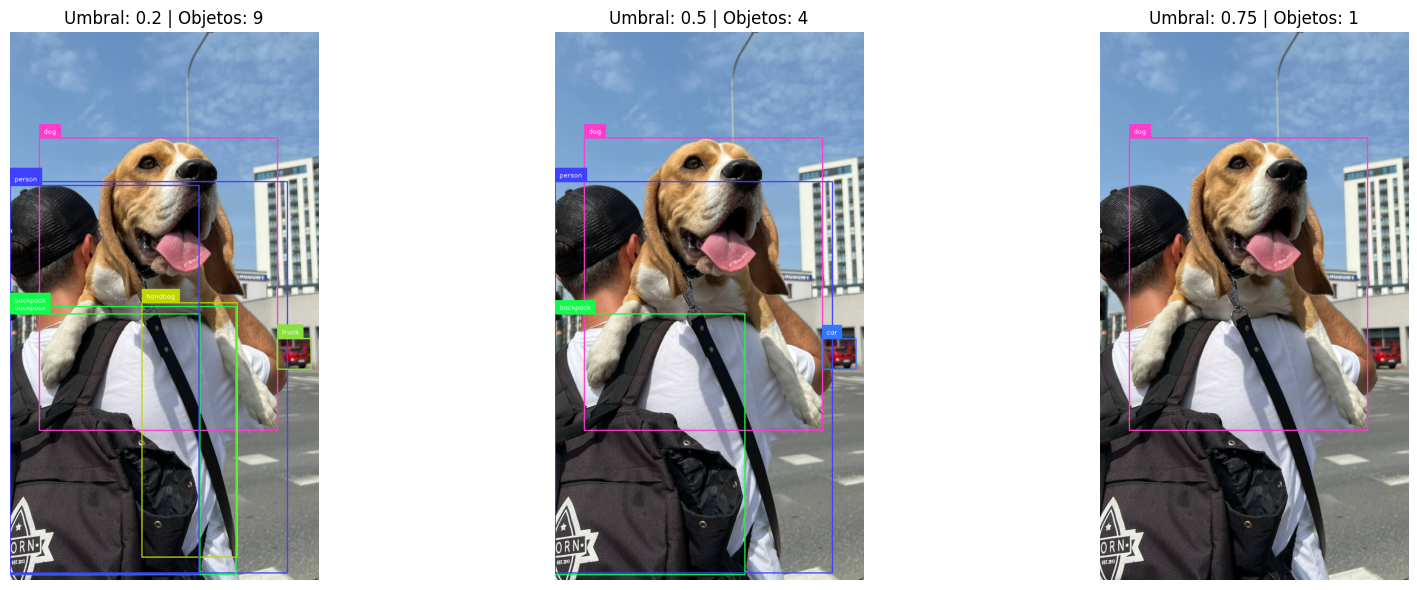

In [ ]:
umbrales = [0.20, 0.50, 0.75]

fig, ejes = plt.subplots(1, 3, figsize=(18, 6))

for ax, umbral in zip(ejes, umbrales):
    det = modelo.predict(imagen, threshold=umbral)

    salida = sv.BoxAnnotator().annotate(
        scene=np.array(imagen).copy(),
        detections=det
    )

    salida = sv.LabelAnnotator().annotate(
        scene=salida,
        detections=det
    )

    ax.imshow(salida)
    ax.set_title(f"Umbral: {umbral} | Objetos: {len(det)}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("Tipo de resultado:", type(detecciones))
print("Atributos disponibles:")

for atributo in dir(detecciones):
    if not atributo.startswith("_"):
        print(atributo)

print("\nCampos de datos adicionales:")
print(list(detecciones.data.keys()))

print("\nMetadatos:")
print(detecciones.metadata)

Tipo de resultado: <class 'supervision.detection.core.Detections'>
Atributos disponibles:
area
box_area
box_aspect_ratio
class_id
confidence
data
empty
from_azure_analyze_image
from_deepsparse
from_detectron2
from_easyocr
from_inference
from_mmdetection
from_ncnn
from_paddledet
from_sam
from_sam3
from_tensorflow
from_transformers
from_ultralytics
from_vlm
from_yolo_nas
from_yolov5
get_anchors_coordinates
get_data
is_empty
mask
merge
metadata
select
to_compact_masks
tracker_id
with_nmm
with_nms
with_soft_nms
xyxy

Campos de datos adicionales:
['source_shape', 'class_name']

Metadatos:
{'source_image': array([[[120, 157, 202],
        [120, 157, 202],
        [120, 157, 202],
        ...,
        [129, 161, 199],
        [128, 160, 198],
        [128, 160, 198]],

       [[119, 156, 201],
        [119, 156, 201],
        [119, 156, 201],
        ...,
        [129, 161, 199],
        [129, 161, 199],
        [128, 160, 198]],

       [[119, 156, 201],
        [119, 156, 201],
        [119

[2026-11-03 18:45:33] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-seg-nano.pt


/root/.roboflow/models/rf-detr-seg-nano.pt:   0%|          | 0.00/128M [00:00<?, ?iB/s]

[2026-11-03 18:45:40] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-seg-nano.pt


[2026-11-03 18:45:40] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-03 18:45:40] [WARNING] rf-detr - Using patch size 12 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-11-03 18:45:41] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-seg-nano.pt already exists with correct MD5 hash.


[2026-11-03 18:45:41] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Objetos segmentados: 3
Campos disponibles: ['source_shape', 'class_name']


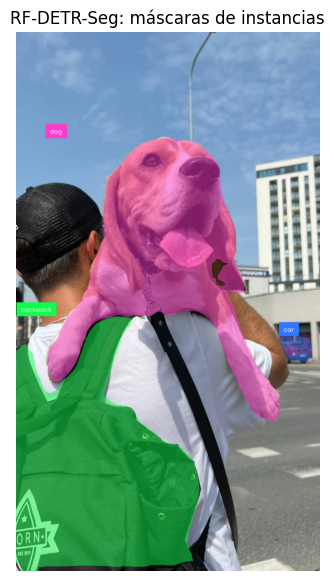

In [ ]:
# Si no existe esta clase en tu instalación, revisa
# las clases mostradas en la celda 2.
from rfdetr import RFDETRSegNano

modelo_seg = RFDETRSegNano()

det_seg = modelo_seg.predict(imagen, threshold=0.5)

print("Objetos segmentados:", len(det_seg))
print("Campos disponibles:", list(det_seg.data.keys()))

imagen_mascaras = sv.MaskAnnotator().annotate(
    scene=np.array(imagen).copy(),
    detections=det_seg
)

imagen_mascaras = sv.LabelAnnotator().annotate(
    scene=imagen_mascaras,
    detections=det_seg
)

plt.figure(figsize=(12, 7))
plt.imshow(imagen_mascaras)
plt.title("RF-DETR-Seg: máscaras de instancias")
plt.axis("off")
plt.show()

In [ ]:
print("Firma del constructor:")
print(inspect.signature(RFDETRSmall))

print("\nFirma de predict:")
print(inspect.signature(modelo.predict))

print("\nFirma de train:")
if hasattr(modelo, "train"):
    print(inspect.signature(modelo.train))
    print(inspect.getdoc(modelo.train))
else:
    print("El método train no está expuesto en esta instancia.")

Firma del constructor:
(*, trust_checkpoint: 'bool' = False, **kwargs: 'Any') -> 'None'

Firma de predict:
(images: 'str | Image.Image | np.ndarray[Any, Any] | torch.Tensor | list[str | np.ndarray[Any, Any] | Image.Image | torch.Tensor]', threshold: 'float' = 0.5, shape: 'tuple[int, int] | None' = None, patch_size: 'int | None' = None, include_source_image: 'bool' = True, **kwargs: 'Any') -> 'Detections | KeyPoints | list[Detections | KeyPoints]'

Firma de train:
(**kwargs: 'Any') -> 'None'
Train an RF-DETR model via the PyTorch Lightning stack.

All keyword arguments are forwarded to :meth:`get_train_config` to build a :class:`~rfdetr.config.TrainConfig`.
Several kwargs are absorbed and handled specially so that existing call-sites do not break:

* ``resolution`` — updates the model's input resolution by mutating
  :attr:`model_config.resolution` in place before the train config is built. This change persists on
  :attr:`model_config` after :meth:`train` returns. The value must be a p

In [ ]:
print("Métodos potencialmente relevantes:\n")

for nombre in dir(modelo):
    if any(palabra in nombre.lower() for palabra in [
        "train", "export", "infer", "predict",
        "config", "checkpoint", "onnx", "engine"
    ]):
        objeto = getattr(modelo, nombre)

        try:
            firma = inspect.signature(objeto)
        except (TypeError, ValueError):
            firma = "(firma no disponible)"

        print(f"{nombre}{firma}")

Métodos potencialmente relevantes:

_detect_num_classes_for_training(dataset_dir: 'str', *, use_grouppose_keypoints: 'bool' = False, coco_categories: 'list[dict[str, Any]] | None' = None) -> 'int'
_ensure_eval_mode_for_unoptimized_inference() -> 'None'
_has_been_trained(firma no disponible)
_has_warned_about_not_being_optimized_for_inference(firma no disponible)
_is_optimized_for_inference(firma no disponible)
_model_config_class(*, encoder: Literal['dinov2_windowed_small', 'dinov2_windowed_base', 'dinov2_registers_windowed_small'] = 'dinov2_windowed_small', out_feature_indexes: list[int] = [3, 6, 9, 12], dec_layers: int = 3, two_stage: bool = True, projector_scale: list[typing.Literal['P3', 'P4', 'P5']] = ['P4'], hidden_dim: int = 256, patch_size: int = 16, num_windows: int = 2, sa_nheads: int = 8, ca_nheads: int = 16, dec_n_points: int = 2, num_queries: int = 300, num_select: int = 300, postprocess_trace_alpha: Annotated[float, Ge(ge=0.0)] = 0.2, bbox_reparam: bool = True, lite_refpo

In [ ]:
subidos = files.upload()

ruta_video = next(iter(subidos))
print("Video seleccionado:", ruta_video)

cap = cv2.VideoCapture(ruta_video)

if not cap.isOpened():
    raise RuntimeError("No se pudo abrir el video.")

fps_original = cap.get(cv2.CAP_PROP_FPS)
ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"Resolución: {ancho} x {alto}")
print(f"FPS originales: {fps_original:.2f}")
print(f"Frames: {total_frames}")
print(f"Duración aproximada: {total_frames / max(fps_original, 1):.1f} s")

cap.release()

Saving 854671-hd_1920_1080_25fps.mp4 to 854671-hd_1920_1080_25fps.mp4
Video seleccionado: 854671-hd_1920_1080_25fps.mp4
Resolución: 1920 x 1080
FPS originales: 25.00
Frames: 1501
Duración aproximada: 60.0 s


In [ ]:
cap = cv2.VideoCapture(ruta_video)

fps = cap.get(cv2.CAP_PROP_FPS)
fps = fps if fps and fps > 0 else 25.0

ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

ruta_salida = "/content/rfdetr_video_resultado.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    ruta_salida, fourcc, fps, (ancho, alto)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("No se pudo crear el video de salida.")

contador = 0
tiempo_inicio = time.perf_counter()

while True:
    correcto, frame_bgr = cap.read()

    if not correcto:
        break

    # OpenCV lee BGR; RF-DETR recibe la imagen en RGB
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    det = modelo.predict(frame_rgb, threshold=0.5)

    anotado_rgb = sv.BoxAnnotator().annotate(
        scene=frame_rgb.copy(),
        detections=det
    )

    anotado_rgb = sv.LabelAnnotator().annotate(
        scene=anotado_rgb,
        detections=det
    )

    anotado_bgr = cv2.cvtColor(
        anotado_rgb, cv2.COLOR_RGB2BGR
    )

    writer.write(anotado_bgr)
    contador += 1

    if contador % 30 == 0:
        print(f"Procesados: {contador} frames")

cap.release()
writer.release()

duracion_proceso = time.perf_counter() - tiempo_inicio

print("Video guardado en:", ruta_salida)
print("Frames procesados:", contador)
print("Tiempo total:", round(duracion_proceso, 2), "s")
print("FPS de procesamiento:", round(
    contador / max(duracion_proceso, 1e-9), 2
))

Procesados: 30 frames
Procesados: 60 frames
Procesados: 90 frames
Procesados: 120 frames
Procesados: 150 frames
Procesados: 180 frames
Procesados: 210 frames
Procesados: 240 frames
Procesados: 270 frames
Procesados: 300 frames
Procesados: 330 frames
Procesados: 360 frames
Procesados: 390 frames
Procesados: 420 frames
Procesados: 450 frames
Procesados: 480 frames
Procesados: 510 frames
Procesados: 540 frames
Procesados: 570 frames
Procesados: 600 frames
Procesados: 630 frames
Procesados: 660 frames
Procesados: 690 frames
Procesados: 720 frames
Procesados: 750 frames
Procesados: 780 frames
Procesados: 810 frames
Procesados: 840 frames
Procesados: 870 frames
Procesados: 900 frames
Procesados: 930 frames
Procesados: 960 frames
Procesados: 990 frames
Procesados: 1020 frames
Procesados: 1050 frames
Procesados: 1080 frames
Procesados: 1110 frames
Procesados: 1140 frames
Procesados: 1170 frames
Procesados: 1200 frames
Procesados: 1230 frames
Procesados: 1260 frames
Procesados: 1290 frames
Proc

In [ ]:
display(Video(ruta_salida, embed=True, width=720))

In [ ]:
files.download(ruta_salida)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>